In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_SPLITS = 5

print("Libraries imported. Random state:", RANDOM_STATE)

Libraries imported. Random state: 42


In [2]:
# OpenML is used because sklearn's old load_boston helper was removed.
housing = fetch_openml(name="boston", version=1, as_frame=True)

X = housing.data.copy()
y = pd.to_numeric(housing.target, errors="coerce")

# Ensure feature columns are numeric for the regression pipelines.
X = X.apply(pd.to_numeric, errors="coerce")
valid_rows = y.notna()
X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

print(f"Rows: {X.shape[0]:,}")
print(f"Features: {X.shape[1]}")
print("Feature names:", list(X.columns))
display(X.head())
display(y.head())

Rows: 506
Features: 13
Feature names: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33


0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
Name: MEDV, dtype: float64

Missing values in features: 0
Duplicate rows: 0

Target summary:


,MEDV
count,506.000000
mean,22.532806
std,9.197104
min,5.000000
25%,17.025000
50%,21.200000
75%,25.000000
max,50.000000


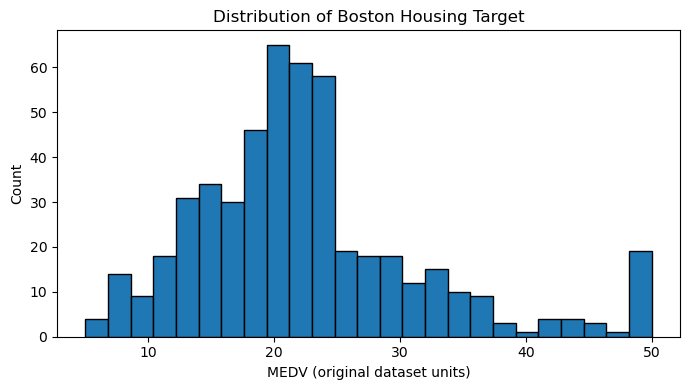

In [3]:
print("Missing values in features:", int(X.isna().sum().sum()))
print("Duplicate rows:", int(X.duplicated().sum()))
print("\nTarget summary:")
display(y.describe().to_frame("MEDV"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(y, bins=25, edgecolor="black")
ax.set_title("Distribution of Boston Housing Target")
ax.set_xlabel("MEDV (original dataset units)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 404
Test rows: 102


In [5]:
cv = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

model_grids = {
    "Linear Regression": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", LinearRegression())
        ]),
        {}
    ),
    "Ridge": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge())
        ]),
        {"model__alpha": [0.1, 1.0, 10.0, 100.0]}
    ),
    "Lasso": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Lasso(max_iter=20000))
        ]),
        {"model__alpha": [0.001, 0.01, 0.1, 1.0, 10.0]}
    ),
    "KNN": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor())
        ]),
        {
            "model__n_neighbors": [3, 5, 7, 9, 13],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    ),
    "SVR": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVR())
        ]),
        {
            "model__kernel": ["rbf", "linear"],
            "model__C": [0.1, 1, 10, 100],
            "model__epsilon": [0.1, 0.2, 0.5]
        }
    ),
    "Decision Tree": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))
        ]),
        {
            "model__max_depth": [None, 3, 5, 8, 12],
            "model__min_samples_leaf": [1, 2, 5, 10]
        }
    ),
    "Random Forest": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
        ]),
        {
            "model__n_estimators": [100, 250],
            "model__max_depth": [None, 8, 15],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": [1.0, 0.8]
        }
    ),
    "Gradient Boosting": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))
        ]),
        {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_depth": [2, 3],
            "model__min_samples_leaf": [1, 3]
        }
    )
}

print(f"Configured {len(model_grids)} candidate algorithms.")

Configured 8 candidate algorithms.


In [6]:
searches = {}
summary_rows = []

for model_name, (pipeline, param_grid) in model_grids.items():
    print(f"Training and tuning: {model_name} ...")
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )
    search.fit(X_train, y_train)
    searches[model_name] = search

    summary_rows.append({
        "Model": model_name,
        "CV RMSE (lower is better)": -search.best_score_,
        "Best parameters": search.best_params_
    })

results = pd.DataFrame(summary_rows).sort_values(
    "CV RMSE (lower is better)", ascending=True
).reset_index(drop=True)

display(results.style.format({"CV RMSE (lower is better)": "{:.4f}"}))

Training and tuning: Linear Regression ...
Training and tuning: Ridge ...
Training and tuning: Lasso ...
Training and tuning: KNN ...
Training and tuning: SVR ...
Training and tuning: Decision Tree ...
Training and tuning: Random Forest ...
Training and tuning: Gradient Boosting ...


,Model,CV RMSE (lower is better),Best parameters
0,Gradient Boosting,3.3400,"{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}"
1,Random Forest,3.6160,"{'model__max_depth': None, 'model__max_features': 0.8, 'model__min_samples_leaf': 1, 'model__n_estimators': 250}"
2,SVR,3.6819,"{'model__C': 100, 'model__epsilon': 0.1, 'model__kernel': 'rbf'}"
3,KNN,4.5054,"{'model__n_neighbors': 3, 'model__p': 1, 'model__weights': 'distance'}"
4,Decision Tree,4.6068,"{'model__max_depth': 8, 'model__min_samples_leaf': 5}"
5,Ridge,4.8591,{'model__alpha': 10.0}
6,Lasso,4.8648,{'model__alpha': 0.01}
7,Linear Regression,4.8663,{}


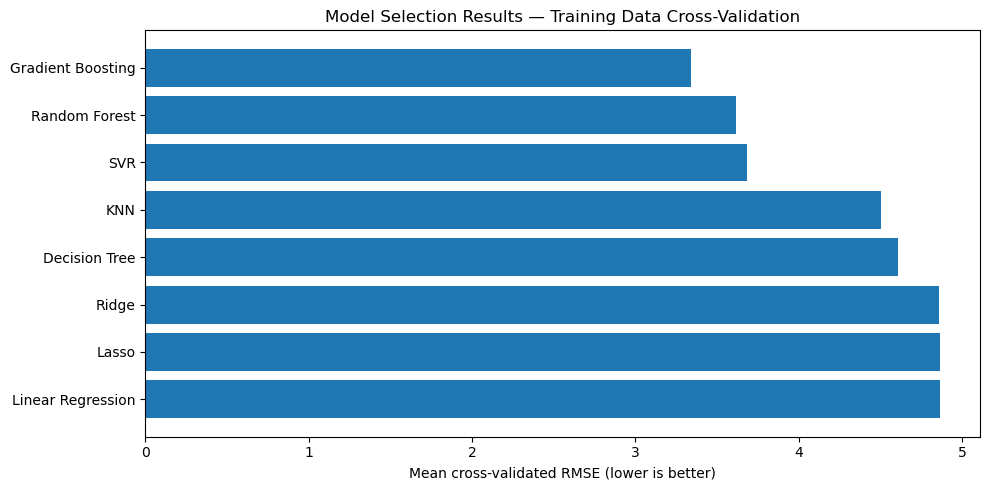

In [7]:
plt.figure(figsize=(10, 5))
plot_results = results.sort_values("CV RMSE (lower is better)", ascending=True)
plt.barh(plot_results["Model"], plot_results["CV RMSE (lower is better)"])
plt.gca().invert_yaxis()
plt.xlabel("Mean cross-validated RMSE (lower is better)")
plt.title("Model Selection Results — Training Data Cross-Validation")
plt.tight_layout()
plt.show()

In [8]:
best_model_name = results.loc[0, "Model"]
best_search = searches[best_model_name]
best_model = best_search.best_estimator_

test_predictions = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_predictions)
test_mse = mean_squared_error(y_test, test_predictions)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, test_predictions)

print("=" * 65)
print("                 BEST MODEL SELECTION REPORT")
print("=" * 65)
print(f"Best model             : {best_model_name}")
print(f"Best CV RMSE           : {-best_search.best_score_:.4f}")
print(f"Test MAE               : {test_mae:.4f}")
print(f"Test MSE               : {test_mse:.4f}")
print(f"Test RMSE              : {test_rmse:.4f}")
print(f"Test R²                : {test_r2:.4f}")
print("\nBest hyperparameters:")
for parameter, value in best_search.best_params_.items():
    print(f"  {parameter}: {value}")
print("\nSelected estimator:")
print(best_model)
print("=" * 65)

                 BEST MODEL SELECTION REPORT
Best model             : Gradient Boosting
Best CV RMSE           : 3.3400
Test MAE               : 1.9260
Test MSE               : 6.1254
Test RMSE              : 2.4750
Test R²                : 0.9165

Best hyperparameters:
  model__learning_rate: 0.05
  model__max_depth: 3
  model__min_samples_leaf: 3
  model__n_estimators: 200

Selected estimator:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 GradientBoostingRegressor(learning_rate=0.05,
                                           min_samples_leaf=3, n_estimators=200,
                                           random_state=42))])


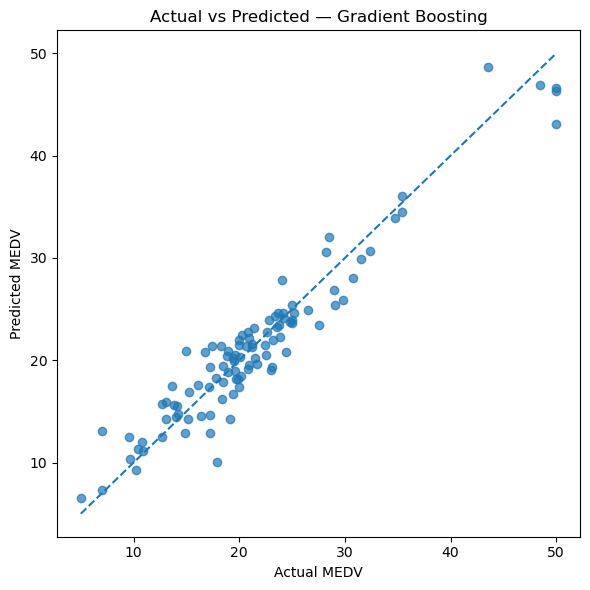

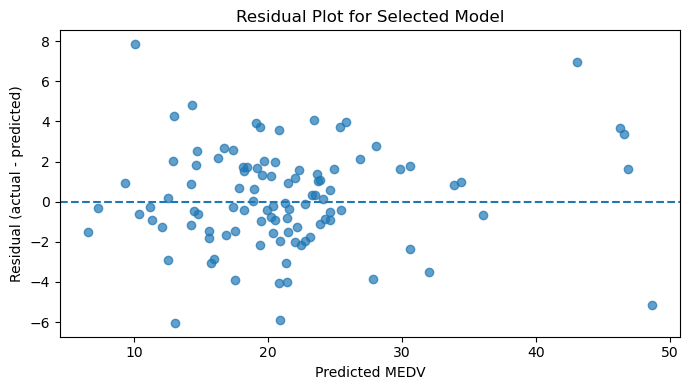

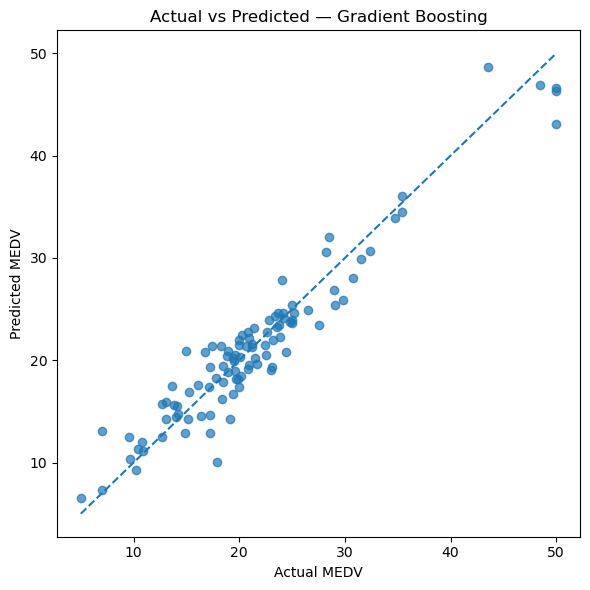

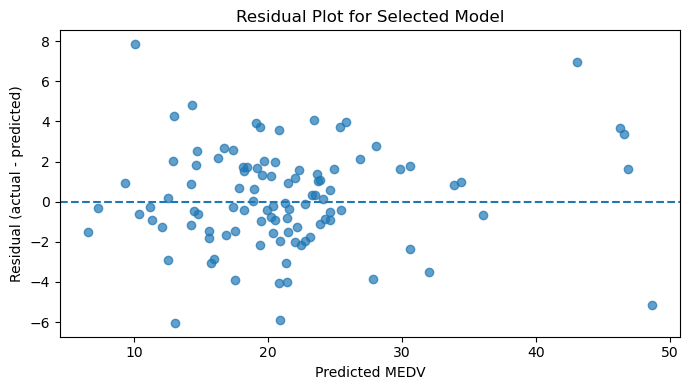

In [14]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, test_predictions, alpha=0.7)
min_value = min(float(y_test.min()), float(test_predictions.min()))
max_value = max(float(y_test.max()), float(test_predictions.max()))
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Actual MEDV")
plt.ylabel("Predicted MEDV")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - test_predictions
plt.figure(figsize=(7, 4))
plt.scatter(test_predictions, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted MEDV")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual Plot for Selected Model")
plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 6))
plt.scatter(y_test, test_predictions, alpha=0.7)
min_value = min(float(y_test.min()), float(test_predictions.min()))
max_value = max(float(y_test.max()), float(test_predictions.max()))
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.xlabel("Actual MEDV")
plt.ylabel("Predicted MEDV")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - test_predictions
plt.figure(figsize=(7, 4))
plt.scatter(test_predictions, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted MEDV")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual Plot for Selected Model")
plt.tight_layout()
plt.show()

Tree-based feature importances:


,Feature,Importance
5,RM,0.425320
12,LSTAT,0.366496
7,DIS,0.073671
10,PTRATIO,0.038077
4,NOX,0.030019
0,CRIM,0.025079
6,AGE,0.012529
9,TAX,0.011939
11,B,0.007700
8,RAD,0.004204


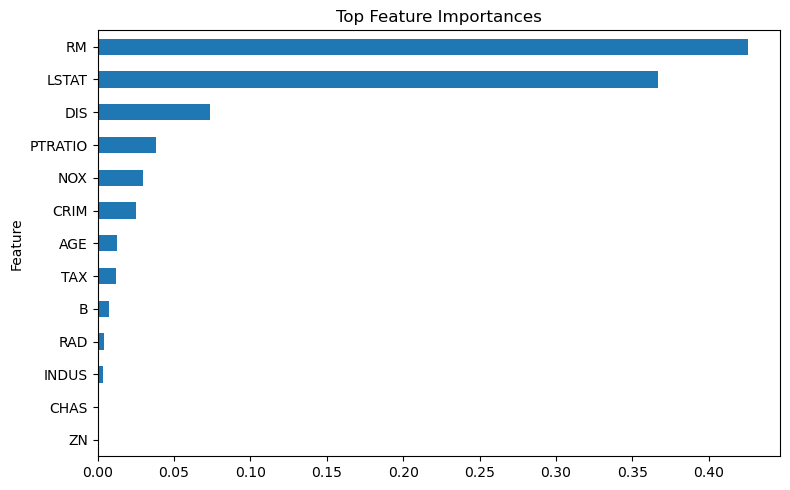

In [12]:
final_estimator = best_model.named_steps["model"]

if hasattr(final_estimator, "feature_importances_"):
    influence = pd.DataFrame({
        "Feature": X.columns,
        "Importance": final_estimator.feature_importances_
    }).sort_values("Importance", ascending=False)
    print("Tree-based feature importances:")
    display(influence.head(15))
    influence.head(15).sort_values("Importance").plot(
        x="Feature", y="Importance", kind="barh", legend=False, figsize=(8, 5)
    )
    plt.title("Top Feature Importances")
    plt.tight_layout()
    plt.show()
elif hasattr(final_estimator, "coef_"):
    coefficients = np.ravel(final_estimator.coef_)
    influence = pd.DataFrame({
        "Feature": X.columns,
        "Coefficient": coefficients
    })
    influence["Absolute coefficient"] = influence["Coefficient"].abs()
    influence = influence.sort_values("Absolute coefficient", ascending=False)
    print("Largest coefficients by absolute value:")
    display(influence.head(15)[["Feature", "Coefficient"]])
else:
    print(f"{best_model_name} does not expose simple coefficients or tree feature importances.")

In [15]:
import joblib
import json
import sklearn

MODEL_PATH = "best_boston_housing_model.joblib"
REPORT_PATH = "best_model_report.json"

joblib.dump(best_model, MODEL_PATH)

report = {
    "dataset": "Boston Housing (OpenML: boston, version 1)",
    "selection_metric": "5-fold cross-validated RMSE",
    "best_model": best_model_name,
    "best_cv_rmse": float(-best_search.best_score_),
    "test_metrics": {
        "MAE": float(test_mae),
        "MSE": float(test_mse),
        "RMSE": float(test_rmse),
        "R2": float(test_r2)
    },
    "best_parameters": best_search.best_params_,
    "scikit_learn_version": sklearn.__version__
}

with open(REPORT_PATH, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2, default=str)

print("Saved model to:", MODEL_PATH)
print("Saved report to:", REPORT_PATH)
print("\nReport contents:")
print(json.dumps(report, indent=2, default=str))

Saved model to: best_boston_housing_model.joblib
Saved report to: best_model_report.json

Report contents:
{
  "dataset": "Boston Housing (OpenML: boston, version 1)",
  "selection_metric": "5-fold cross-validated RMSE",
  "best_model": "Gradient Boosting",
  "best_cv_rmse": 3.339958516860475,
  "test_metrics": {
    "MAE": 1.9259915991260266,
    "MSE": 6.125406343275959,
    "RMSE": 2.474955826530235,
    "R2": 0.9164722440422235
  },
  "best_parameters": {
    "model__learning_rate": 0.05,
    "model__max_depth": 3,
    "model__min_samples_leaf": 3,
    "model__n_estimators": 200
  },
  "scikit_learn_version": "1.7.2"
}


In [16]:
sample = X_test.iloc[[0]].copy()
prediction = best_model.predict(sample)[0]

print("Input feature values:")
display(sample)
print(f"Predicted MEDV: {prediction:.3f}")
print("Reminder: MEDV is expressed in the original dataset's units (historically thousands of dollars).")

Input feature values:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
173,0.09178,0.0,4.05,0,0.51,6.416,84.1,2.6463,5,296.0,16.6,395.5,9.04


Predicted MEDV: 23.272
Reminder: MEDV is expressed in the original dataset's units (historically thousands of dollars).
